# Weekend Assignment 02: End-to-End Regression Project
## Medical Insurance Cost Prediction: From Raw Data to a Reusable Model

**Goal:** predict the yearly medical insurance `charges` of a person from `age`, `sex`, `bmi`, `children`, `smoker` and `region`.

**Pipeline:** Explore → Engineer features → Build 3 regression models → Evaluate → Select & interpret → Save & reuse the model.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   # one seed used everywhere so all comparisons are fair

## 1. Data Loading & Exploration
First we upload `insurance.csv` (Colab upload widget), then inspect shape, types, summary statistics, missing values and duplicates.

In [2]:
# --- Upload (Colab). If you run locally and the file is next to the notebook, this is skipped. ---
try:
    from google.colab import files
    uploaded = files.upload()          # choose insurance.csv
except ImportError:
    pass

df = pd.read_csv("insurance.csv")
df.head()

Saving insurance.csv to insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
print("Shape:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics (numeric):")
display(df.describe())
print("Categorical value counts:")
for c in ["sex", "smoker", "region"]:
    print(df[c].value_counts(), "\n")

Shape: (1338, 7)

Column types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1

Summary statistics (numeric):


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Categorical value counts:
sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 



In [4]:
# One exact duplicate row exists -> it adds no new information and could leak between train/test, so we drop it.
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1337, 7)


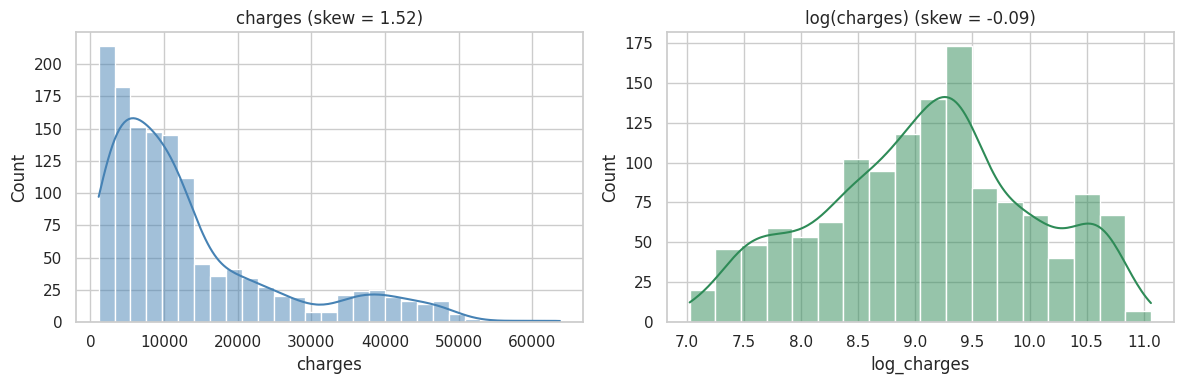

In [5]:
# --- Target variable: is `charges` skewed? ---
df["log_charges"] = np.log(df["charges"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["charges"], kde=True, ax=ax[0], color="steelblue")
ax[0].set_title(f"charges (skew = {df['charges'].skew():.2f})")
sns.histplot(df["log_charges"], kde=True, ax=ax[1], color="seagreen")
ax[1].set_title(f"log(charges) (skew = {df['log_charges'].skew():.2f})")
plt.tight_layout(); plt.show()

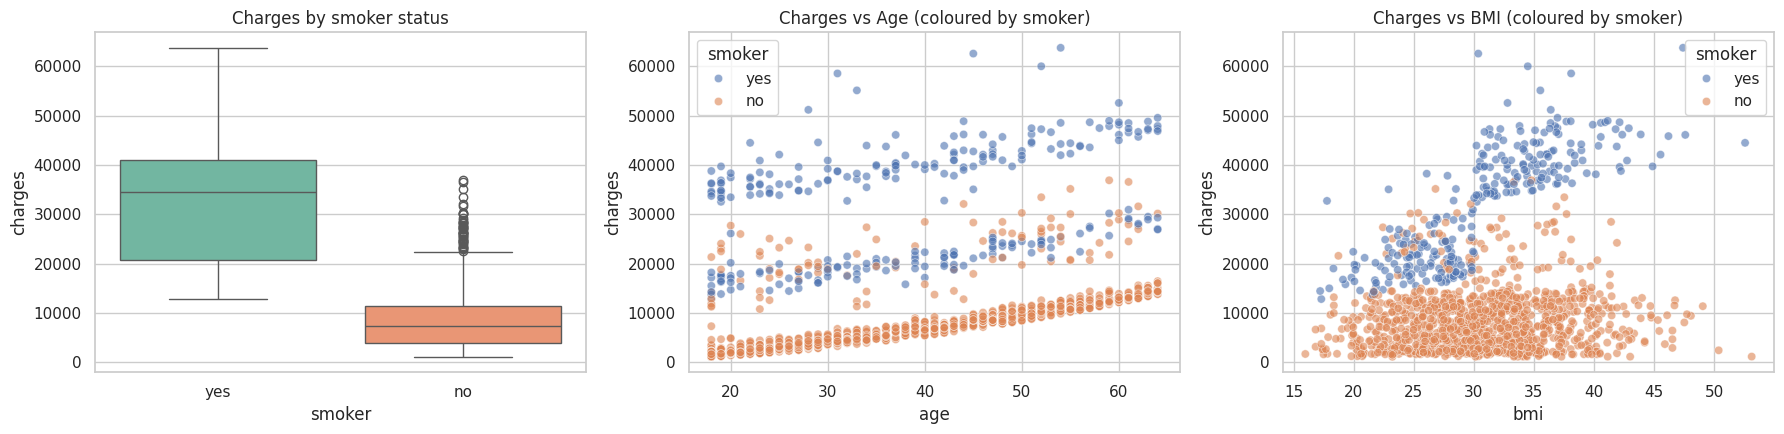

           mean   median  count
smoker                         
no       8441.0   7346.0   1063
yes     32050.0  34456.0    274


In [6]:
# --- Relationship of charges with smoker, age and BMI ---
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=df, x="smoker", y="charges", ax=ax[0], palette="Set2")
ax[0].set_title("Charges by smoker status")
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=.6, ax=ax[1])
ax[1].set_title("Charges vs Age (coloured by smoker)")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=.6, ax=ax[2])
ax[2].set_title("Charges vs BMI (coloured by smoker)")
plt.tight_layout(); plt.show()

print(df.groupby("smoker")["charges"].agg(["mean", "median", "count"]).round(0))

### Exploration findings
* **No missing values**, and only **1 duplicate row** (removed).
* **`charges` is right-skewed** (skewness ≈ 1.5): most people pay a little, a few pay a lot (up to ≈ \$64k). A skewed target breaks the "roughly normal residuals" assumption of linear regression, and the largest values would dominate the squared error. After a log transform the shape is much more symmetric.
* **Smoking is by far the strongest driver:** smokers pay on average about **4× more** than non-smokers (≈ \$32k vs ≈ \$8.4k).
* **Age** raises cost steadily; in the age plot you can see three "bands" (non-smokers, smokers, and a high band).
* **BMI** matters mainly for **smokers with BMI ≥ 30**: the highest-cost cluster is smokers who are obese. This suggests an **interaction effect**, which we will capture with engineered features.

## 2. Feature Engineering

**Encoding choices (with justification)**

| Column | Type | Method | Why |
|---|---|---|---|
| `sex` | binary | Label encode (male = 1, female = 0) | Only 2 categories; one 0/1 column carries all the information. |
| `smoker` | binary | Label encode (yes = 1, no = 0) | Same reason; 0/1 also keeps the coefficient easy to interpret. |
| `region` | nominal, 4 categories | One-hot encode (`drop_first=True`) | Regions have **no natural order**; label encoding (0,1,2,3) would falsely tell a linear model that southwest > southeast. We drop one dummy to avoid the dummy-variable trap (perfect multicollinearity). |

**Derived features (my own)**
* `bmi_obese`: 1 if BMI ≥ 30 (the standard medical threshold for obesity).
* `smoker_obese`: `smoker × bmi_obese` interaction (suggested by the plots above).
* `age_x_smoker`: `age × smoker` interaction, because the cost of ageing differs for smokers.

In [7]:
data = df.copy()

# Binary columns -> label encoding
data["sex_male"] = (data["sex"] == "male").astype(int)
data["smoker_yes"] = (data["smoker"] == "yes").astype(int)

# Nominal column -> one-hot (drop_first avoids the dummy-variable trap)
data = pd.get_dummies(data, columns=["region"], drop_first=True, dtype=int)

# Derived features
data["bmi_obese"] = (data["bmi"] >= 30).astype(int)
data["smoker_obese"] = data["smoker_yes"] * data["bmi_obese"]
data["age_x_smoker"] = data["age"] * data["smoker_yes"]

data = data.drop(columns=["sex", "smoker"])
data.head()

,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_obese,smoker_obese,age_x_smoker
0,19,27.900,0,16884.92400,9.734176,0,1,0,0,1,0,0,19
1,18,33.770,1,1725.55230,7.453302,1,0,0,1,0,1,0,0
2,28,33.000,3,4449.46200,8.400538,1,0,0,1,0,1,0,0
3,33,22.705,0,21984.47061,9.998092,1,0,1,0,0,0,0,0
4,32,28.880,0,3866.85520,8.260197,1,0,1,0,0,0,0,0


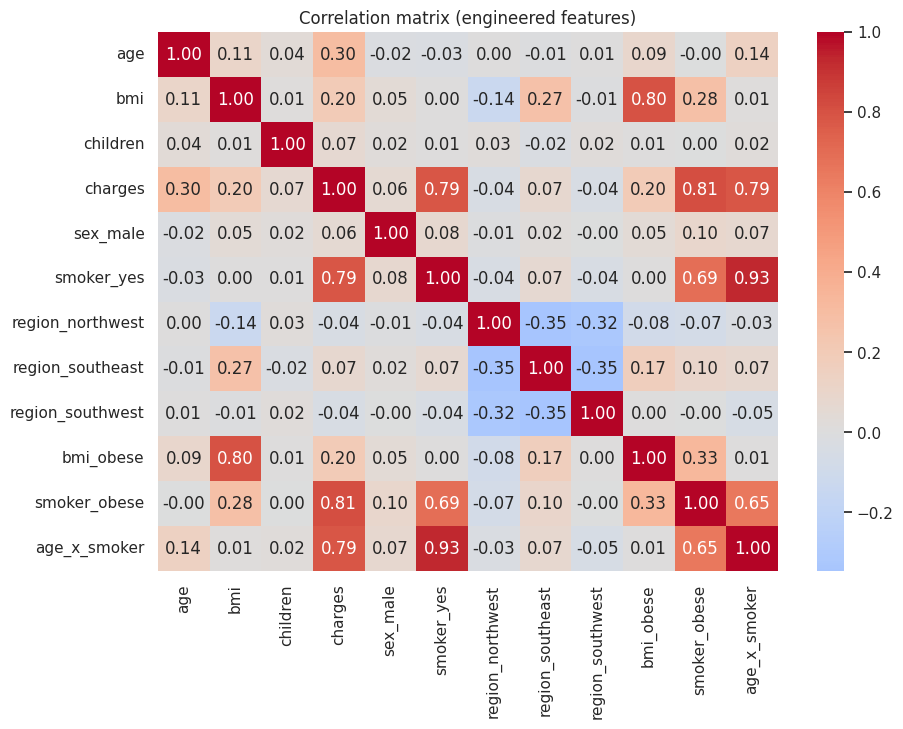

smoker_obese        0.815
age_x_smoker        0.789
smoker_yes          0.787
age                 0.298
bmi_obese           0.200
bmi                 0.198
region_southeast    0.074
children            0.067
sex_male            0.058
region_northwest   -0.039
region_southwest   -0.044
Name: charges, dtype: float64


In [8]:
# Correlation of every engineered feature with the (raw) target
plt.figure(figsize=(10, 7))
sns.heatmap(data.drop(columns="log_charges").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (engineered features)")
plt.show()

print(data.drop(columns="log_charges").corr()["charges"].drop("charges").sort_values(ascending=False).round(3))

### Target transformation & scaling
* **Log transform:** we model `log(charges)` instead of `charges` because the target is right-skewed (see Section 1). This stabilises the variance of the errors and makes effects *multiplicative* (e.g. "smoking multiplies the cost by X"), which fits insurance pricing well. **All metrics below are reported back in dollars** (`np.exp` of the prediction) so they are interpretable.
* **Scaling:** linear/polynomial regression can work unscaled, but scaling puts the coefficients on a comparable footing and is essential for polynomial terms (age², bmi² are huge numbers). We scale only the **continuous** columns and keep 0/1 columns untouched so their coefficients stay easy to read. The scaler is placed **inside a Pipeline**, so it is fit on the training data only (no data leakage).

## 3. Model Building
We use **one single train/test split** (80/20, `random_state=42`) for all three models so the comparison is fair.

In [9]:
FEATURES = [c for c in data.columns if c not in ["charges", "log_charges"]]
X = data[FEATURES]
y_log = data["log_charges"]

X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=RANDOM_STATE
)
y_test = np.exp(y_test_log)    # true charges in dollars, for the metrics

print("Features used:", FEATURES)
print("Train:", X_train.shape, " Test:", X_test.shape)

def evaluate(name, model, cols):
    """Fit on train, predict test, return metrics in DOLLARS (plus R² on the log scale)."""
    model.fit(X_train[cols], y_train_log)
    pred_log = model.predict(X_test[cols])
    pred = np.exp(pred_log)
    mse = mean_squared_error(y_test, pred)
    return {"Model": name,
            "R2": r2_score(y_test, pred),
            "MAE": mean_absolute_error(y_test, pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R2 (log scale)": r2_score(y_test_log, pred_log)}

results, fitted = [], {}

Features used: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_obese', 'smoker_obese', 'age_x_smoker']
Train: (1069, 11)  Test: (268, 11)


In [10]:
# --- Model 1: Simple Linear Regression, one feature only ---
# Choice: `smoker_yes`. It has by far the highest correlation with charges among the raw features (≈ 0.79).
m1 = LinearRegression()
results.append(evaluate("1. Simple LR (smoker)", m1, ["smoker_yes"]))
fitted["1. Simple LR (smoker)"] = (m1, ["smoker_yes"])
print("Intercept:", round(m1.intercept_, 3), " Slope:", round(m1.coef_[0], 3))

Intercept: 8.795  Slope: 1.48


In [11]:
# --- Model 2: Multiple Linear Regression with ALL engineered features ---
CONTINUOUS = ["age", "bmi", "children", "age_x_smoker"]

pre_linear = ColumnTransformer(
    [("scale", StandardScaler(), CONTINUOUS)],
    remainder="passthrough", verbose_feature_names_out=False
)
m2 = Pipeline([("prep", pre_linear), ("lr", LinearRegression())])
results.append(evaluate("2. Multiple LR (all features)", m2, FEATURES))
fitted["2. Multiple LR (all features)"] = (m2, FEATURES)
print("Done:", results[-1]["Model"])

Done: 2. Multiple LR (all features)


In [12]:
# --- Model 3: Polynomial Regression on the numeric features age and bmi ---
# Choose the degree with 5-fold CV on the TRAINING data only (the test set stays untouched).
def make_poly_model(degree):
    pre = ColumnTransformer(
        [("poly", Pipeline([("p", PolynomialFeatures(degree, include_bias=False)),
                            ("s", StandardScaler())]), ["age", "bmi"]),
         ("scale", StandardScaler(), ["children", "age_x_smoker"])],
        remainder="passthrough", verbose_feature_names_out=False
    )
    return Pipeline([("prep", pre), ("lr", LinearRegression())])

kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
for d in [1, 2, 3, 4]:
    s = cross_val_score(make_poly_model(d), X_train, y_train_log, cv=kf, scoring="r2")
    print(f"degree {d}: mean CV R² (log scale, train only) = {s.mean():.4f}")

degree 1: mean CV R² (log scale, train only) = 0.8096
degree 2: mean CV R² (log scale, train only) = 0.8115
degree 3: mean CV R² (log scale, train only) = 0.8105
degree 4: mean CV R² (log scale, train only) = 0.8092


In [13]:
DEGREE = 2   # chosen above: going beyond 2 gives no meaningful gain (extra complexity, overfitting risk)
m3 = make_poly_model(DEGREE)
results.append(evaluate(f"3. Polynomial LR (age, bmi, deg {DEGREE})", m3, FEATURES))
fitted[f"3. Polynomial LR (age, bmi, deg {DEGREE})"] = (m3, FEATURES)
print("Done:", results[-1]["Model"])

Done: 3. Polynomial LR (age, bmi, deg 2)


## 4. Model Evaluation
All metrics are computed on the **same hold-out test set**, in **dollars**. Reminder:
* **R²**: share of the variance explained (1 = perfect).
* **MAE**: average absolute error in dollars (easy to read, not dominated by outliers).
* **MSE / RMSE**: penalise large errors more strongly; RMSE is in dollars.

In [14]:
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.style.format({"R2": "{:.4f}", "MAE": "{:,.0f}", "MSE": "{:,.0f}",
                                 "RMSE": "{:,.0f}", "R2 (log scale)": "{:.4f}"})
        .highlight_max(subset=["R2", "R2 (log scale)"], color="#c8f7c5")
        .highlight_min(subset=["MAE", "MSE", "RMSE"], color="#c8f7c5"))

,R2,MAE,MSE,RMSE,R2 (log scale)
Model,,,,,
1. Simple LR (smoker),0.6357,"5,980","66,945,660","8,182",0.4992
2. Multiple LR (all features),0.8801,"2,445","22,033,212","4,694",0.8776
"3. Polynomial LR (age, bmi, deg 2)",0.8701,"2,552","23,866,140","4,885",0.8803


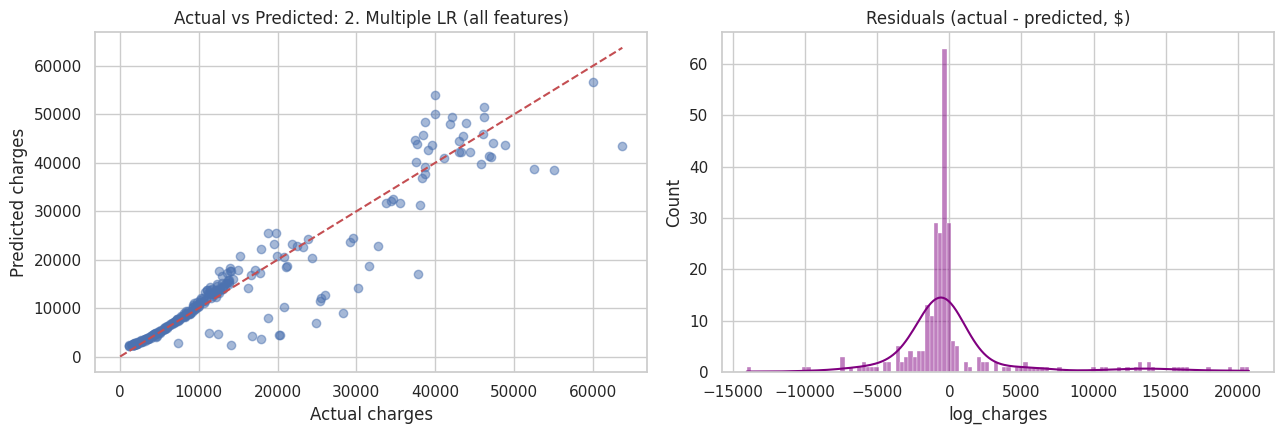

Best model by RMSE: 2. Multiple LR (all features)


In [15]:
# Visual check of the best model: predicted vs actual, and residuals
best_name = comparison["RMSE"].idxmin()
best_model, best_cols = fitted[best_name]
best_pred = np.exp(best_model.predict(X_test[best_cols]))
resid = y_test - best_pred

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, best_pred, alpha=.5)
lim = [0, max(y_test.max(), best_pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual charges"); ax[0].set_ylabel("Predicted charges")
ax[0].set_title(f"Actual vs Predicted: {best_name}")
sns.histplot(resid, kde=True, ax=ax[1], color="purple")
ax[1].set_title("Residuals (actual - predicted, $)")
plt.tight_layout(); plt.show()
print("Best model by RMSE:", best_name)

In [16]:
# --- 5-fold cross-validation of the best model on the whole dataset ---
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
r2_dollars, r2_logs = [], []
for tr, te in kf.split(X):
    mdl = clone(best_model)                        # fresh, unfitted copy of the same pipeline
    mdl.fit(X.iloc[tr][best_cols], y_log.iloc[tr])
    p = mdl.predict(X.iloc[te][best_cols])
    r2_logs.append(r2_score(y_log.iloc[te], p))
    r2_dollars.append(r2_score(np.exp(y_log.iloc[te]), np.exp(p)))

print("R² per fold (dollars):", np.round(r2_dollars, 4))
print(f"Average R² (dollars):   {np.mean(r2_dollars):.4f}  (std {np.std(r2_dollars):.4f})")
print(f"Average R² (log scale): {np.mean(r2_logs):.4f}")

R² per fold (dollars): [0.8801 0.7937 0.7889 0.8341 0.8263]
Average R² (dollars):   0.8246  (std 0.0329)
Average R² (log scale): 0.8251


## 5. Model Selection & Interpretation

**Results on the test set (dollars)**

| Model | R² | MAE | RMSE |
|---|---|---|---|
| 1. Simple LR (smoker) | 0.636 | \$5,980 | \$8,182 |
| 2. Multiple LR (all features) | **0.880** | **\$2,445** | **\$4,694** |
| 3. Polynomial LR (age, bmi, deg 2) | 0.870 | \$2,552 | \$4,885 |

**Chosen model: Model 2, Multiple Linear Regression with all engineered features.** I did not choose it just because its R² is highest; the reasons are:
1. **It wins on every dollar-scale metric** (R², MAE, MSE and RMSE), not only one of them.
2. **The polynomial model adds complexity without a real gain.** Cross-validation on the training data barely changed between degree 1 and degree 2 (0.8096 → 0.8115), and in dollars it is slightly *worse* than the linear model. It is marginally better on the log scale (0.8803 vs 0.8776), but that difference is negligible. Age and BMI effects are already well captured by the engineered interaction features, so the squared terms mostly add noise.
3. **Interpretability.** Model 2 has one coefficient per feature, which lets us explain *why* a price is high. This matters for insurance pricing.
4. **Simple LR is clearly not enough.** One yes/no feature can only split people into two price groups (R² = 0.64, average error ≈ \$6,000). It ignores age and BMI.
5. **5-fold cross-validation** of Model 2 gives an average R² of about **0.825** (folds range from 0.79 to 0.88). This is a bit lower than the 0.880 on the single test split, so that particular split was slightly favourable. The honest expectation for new customers is **R² ≈ 0.82**, with an average error of a few thousand dollars.

**Limitation:** the errors are larger for very expensive customers (see the residual plot). A non-linear model such as Random Forest or Gradient Boosting could improve this.

,coefficient (log scale),"approx. effect on cost (%, per 1 SD for scaled cols)"
smoker_yes,2.478,1091.872
smoker_obese,0.699,101.269
age,0.577,78.068
age_x_smoker,-0.557,-42.685
region_southwest,-0.133,-12.449
children,0.130,13.851
region_southeast,-0.100,-9.499
sex_male,-0.080,-7.691
region_northwest,-0.025,-2.458
bmi_obese,-0.019,-1.852


Cost increase per extra year of age - non-smoker: 4.2% | smoker: 0.7%


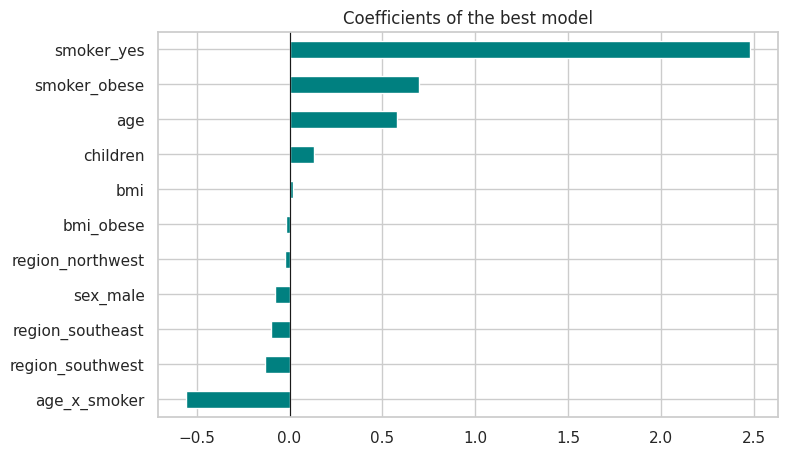

In [17]:
# Coefficients of the best model (continuous features are standardised; 0/1 features are not)
prep = best_model.named_steps["prep"]
names = prep.get_feature_names_out()
coefs = pd.Series(best_model.named_steps["lr"].coef_, index=names)

coef_table = pd.DataFrame({
    "coefficient (log scale)": coefs,
    "approx. effect on cost (%, per 1 SD for scaled cols)": (np.exp(coefs) - 1) * 100,
}).sort_values("coefficient (log scale)", key=abs, ascending=False)
display(coef_table.round(3))

# Age effect per YEAR (undo the standardisation): non-smokers vs smokers
scales = dict(zip(CONTINUOUS, prep.named_transformers_["scale"].scale_))
b_age, b_int = coefs["age"] / scales["age"], coefs["age_x_smoker"] / scales["age_x_smoker"]
print(f"Cost increase per extra year of age - non-smoker: {(np.exp(b_age)-1)*100:.1f}% | smoker: {(np.exp(b_age+b_int)-1)*100:.1f}%")

coef_table["coefficient (log scale)"].sort_values().plot.barh(figsize=(8, 5), color="teal")
plt.title("Coefficients of the best model"); plt.axvline(0, color="k", lw=.8); plt.show()

### Interpretation of the coefficients
Continuous features are standardised (coefficients are "per 1 standard deviation") and the target is log-scaled, so a coefficient `b` means cost changes by about `(e^b − 1) × 100 %`.

* **`smoker_yes` is by far the largest coefficient (≈ 2.5).** Smoking multiplies the predicted cost several times over. This matches the exploration step, where smokers paid about 4× more on average.
* **`smoker_obese` (≈ +0.70)** roughly doubles the cost again for smokers who are obese. This confirms what the BMI scatter plot suggested: BMI is expensive *only in combination with smoking*.
* **Age is the second driver.** Each extra year raises the cost by about 4% for non-smokers, but only about 1% for smokers (the negative `age_x_smoker` coefficient). Smokers start from a high base, so ageing adds proportionally less.
* **`bmi` and `bmi_obese` alone are almost zero.** This is a small surprise: BMI by itself is not a strong driver once smoking is accounted for.
* **`children`, `region` and `sex` have small effects** (a few percent), consistent with the weak correlations seen in the heatmap.

Overall the model agrees with the exploration: **smoking status ≫ age > (obesity × smoking) > everything else.**

## 6. Lightweight Model Deployment
We save the trained model (together with the exact feature list it expects) using `joblib`, then write `predict_insurance_cost(...)`, which **loads the file from disk** and predicts for a new person. No retraining is needed.

In [18]:
MODEL_FILE = "insurance_model.joblib"

artifact = {
    "model": best_model,                 # fitted pipeline (scaler + regression)
    "feature_columns": best_cols,        # exact column order the model was trained on
    "target_transform": "log",           # model predicts log(charges) -> we apply exp()
}
joblib.dump(artifact, MODEL_FILE)
print("Saved:", MODEL_FILE)

Saved: insurance_model.joblib


In [19]:
# --- Also save a .pkl version and download both model files to your computer ---
import pickle

PKL_FILE = "insurance_model.pkl"
with open(PKL_FILE, "wb") as f:
    pickle.dump(artifact, f)
print("Saved:", PKL_FILE)

# Download both files from Colab (browser may ask permission for multiple downloads -> Allow)
try:
    from google.colab import files
    files.download(MODEL_FILE)
    files.download(PKL_FILE)
except ImportError:
    print("Not running in Colab: files are saved next to the notebook.")

Saved: insurance_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
def predict_insurance_cost(age, sex, bmi, children, smoker, region):
    """Load the saved model and return the predicted yearly insurance cost (in dollars).

    sex: 'male'/'female' | smoker: 'yes'/'no' | region: 'northeast','northwest','southeast','southwest'
    """
    sex, smoker, region = sex.lower().strip(), smoker.lower().strip(), region.lower().strip()
    assert sex in ("male", "female"), "sex must be 'male' or 'female'"
    assert smoker in ("yes", "no"), "smoker must be 'yes' or 'no'"
    assert region in ("northeast", "northwest", "southeast", "southwest"), "unknown region"

    art = joblib.load(MODEL_FILE)                      # load the saved model (no retraining)

    smoker_yes = int(smoker == "yes")
    bmi_obese = int(bmi >= 30)
    row = {
        "age": age, "bmi": bmi, "children": children,
        "sex_male": int(sex == "male"), "smoker_yes": smoker_yes,
        "region_northwest": int(region == "northwest"),
        "region_southeast": int(region == "southeast"),
        "region_southwest": int(region == "southwest"),
        "bmi_obese": bmi_obese,
        "smoker_obese": smoker_yes * bmi_obese,
        "age_x_smoker": age * smoker_yes,
    }
    X_new = pd.DataFrame([row])[art["feature_columns"]]
    return float(np.exp(art["model"].predict(X_new))[0])

# --- Test with hypothetical people ---
tests = [
    dict(age=25, sex="female", bmi=22.0, children=0, smoker="no",  region="northeast"),
    dict(age=45, sex="male",   bmi=33.5, children=2, smoker="yes", region="southeast"),
    dict(age=60, sex="female", bmi=28.0, children=1, smoker="no",  region="southwest"),
]
for t in tests:
    print(f"{t}\n   -> predicted cost: ${predict_insurance_cost(**t):,.2f}\n")

{'age': 25, 'sex': 'female', 'bmi': 22.0, 'children': 0, 'smoker': 'no', 'region': 'northeast'}
   -> predicted cost: $3,537.06

{'age': 45, 'sex': 'male', 'bmi': 33.5, 'children': 2, 'smoker': 'yes', 'region': 'southeast'}
   -> predicted cost: $44,664.81

{'age': 60, 'sex': 'female', 'bmi': 28.0, 'children': 1, 'smoker': 'no', 'region': 'southwest'}
   -> predicted cost: $14,883.16



In [21]:
# Sanity check: the loaded-from-disk model gives the same answer as the in-memory model for a real test row
i = X_test.index[0]
mem = float(np.exp(best_model.predict(X_test.loc[[i], best_cols]))[0])
r = df.loc[i]
disk = predict_insurance_cost(r["age"], r["sex"], r["bmi"], r["children"], r["smoker"], r["region"])
print(f"In-memory: {mem:,.2f} | From disk: {disk:,.2f} | Actual: {r['charges']:,.2f}")

In-memory: 8,797.85 | From disk: 8,797.85 | Actual: 8,688.86


## Conclusion
* Built a full pipeline: cleaning → exploration → feature engineering → 3 regression models → evaluation → saved model.
* Smoking status (and its interactions with age and obesity) dominates insurance cost; age and BMI come next; sex, region and number of children matter little.
* The saved file `insurance_model.joblib` plus `predict_insurance_cost()` lets anyone get a prediction without retraining.

**Limitations / next steps:** a linear model on a log target can't capture every non-linearity; try Ridge/Lasso, Random Forest or Gradient Boosting, and add residual-based checks per group.